In [1]:
import os
import os.path
import cv2 as cv
from PIL import Image
import numpy as np
import pandas as pd
import random as rand

Data:You have been provided with 8 H&E files starting with letters A-D. 
This is grouped as bellow:
Group A: A1, A2 (For Model 1 described below)
Group B: B1, B2 (For Model 1 described below)
Group C: C1, C2 (For Model 2 described below)
Group D: D1, D2 (For Model 2 described below)

Using the image analysis workflow from our practical in the AI in pathology image analysis, process the images into patches of 100 by 100.\
Then, generate the train and test set using 90:10 ratio. 

Finally, create two CNN models to predict 1) A vs B and 2) C vs D. i.e., 
Model 1: Use the A and B images to build the model.
Model 2: Use the C and D images to build the model.
(Note: You are allowed to modify (add or remove) the Con2D layers to improve the performance)


In [2]:
# ---------------- Function 1: Calculate much of a tile is background ----------------

# n is the image tile 
def tissue_percent(n):
    
# check the array has 3 dimensions (height, width, and channels)
    # n.shape[2] == 3 confirms there are exactly 3 colour channels 
    if(len(n.shape) ==3) and (n.shape[2] == 3):      
        # Add all the pixel values from the three channels --> we collapse the colour image into a 2D layer
        # adds red to 0, green to 1 and blue to 2
        ## if the pixel is [0,0,0] = pure black the the sum remains 0.
        # a combined channel
        n_s = n[:, :, 0] + n[:, :, 1] + n[:, :, 2]
        # The calculate the percentage of nonzero - see what is not a pure black background
        mask_p = 100 - (np.count_nonzero(n_s) / n_s.size * 100)

        # handling grayscale images = standard colour images have 3 layers = red, green, blue. many medical images are grayscale
# if you pass a grayscale image to the first part of the code, n.shape[2] would cause an error because there is no third dimension
    
    else: # else statement ensures the function doesnt crash if it encounters an image that doesnt fit RGB structure 
        # Sometimes the image could have an odd shape, hence the above condition will not work 
        # To solve the problem we create an edge case switch
        # if the image isnt a standard 3-channel RGB image (e.g. grayscale) we still do the same calculation
        mask_p = 100 - np.count_nonzero(n) / n.size * 100
    # return background percentage
    return 100 - mask_p

# ---------------- Function 2: Slice the whole image into fixed-sized tiles ----------------
# as whole slide images are big, consisting of gigapixels we need to chop each image into 100x100 pixel patches (Kani et al., 2025)
# d=200 is tile size in pixels; thresh=20 is a background threshold of 20%, name = label prefix 

def fixed_cube(img, tile_size=200, thresh=20, name="base"): 
    # create an empty dictionary to store accepted tiles 
    cubes = dict()
    # counter to number each tile, starts at 0 and goes up by 1 whenever a tile is looked at
    n = 0 

    # move down the image in terms of tile_size, it will stop before the last tile so it doesnt go out of bounds
    for x in range(0, img.shape[0] - tile_size, tile_size):

        # move across width of image starting at x(-tile_size) and y(tile_size). it will stop before going out of bounds
        for y in range(0, img.shape[1] - tile_size, tile_size):

            # crop tile_size x tile_size from the image at position (x, y) 
            window = img[x:x + tile_size, y:y + tile_size, :] 
            # check how much of the tile is background
            tile_content = tissue_percent(window) 

            # if there is enough tissue in the tile we print: 
            if tile_content >= thresh: 
                print("Tile {} is good".format(n)) 
                # and save the tile into the cubes dictionary
                cubes[name + str(n)] = window 
            else:
                # otherwise skip it and print:
                print("Tile {} is bad".format(n))
                
            # then move onto the next tile
            n += 1 
        # then we return all the good tiles 
    return cubes 

# ---------------- Function 3: convert numpy array and save it as image file  ----------------

def save_image(img, path): 
    # only run the function if the tile has data 
    if img is not None:
        # if pixel values are true or false then convert it to black or white. (Data types — NumPy v2.4 Manual, no date)
        # true = white, and false = black
        if img.dtype == "bool":
            img = img.astype("uint8") * 255
        # if a pixel value is a decimal between 0 and 1 then it is converted to a whole number (Data types — NumPy v2.4 Manual, no date)
        elif img.dtype == "float64":
            img = (img * 255).astype("uint8")

        # convert numpy array into pil image 
        img = Image.fromarray(img)
        img.save(path) # save image 
    return 

# ---------------- Function 4: save all tiles from dictionary to folder  ----------------

# the function takes all the tiles that were saved to dictionary cube 
def save_tiles(cube, path):
    # if the output folder does not exist we create the folder
    if not os.path.exists(path):
        os.makedirs(path)

    # then look through every time in the dictionary and save each tile as a jpg file
    for z in cube:
        save_image(cube[z], os.path.join(path, z + ".jpg"))
    print("Done")
    return

# comments and code adapted from Anene (2026)

In [3]:
# ---------------- Load in the images  ----------------

# load each H&E whole slide image and tile it into 100x100 
# images with more than 20% white background are discarded
# label each image with the sample name

# group A: A1 + A2
A1_cubes = fixed_cube(cv.imread("A1.jpg"), tile_size=100, thresh=20, name="A1_")
A2_cubes = fixed_cube(cv.imread("A2.jpg"), tile_size=100, thresh=20, name="A2_")

# group B: B1 + B2
B1_cubes = fixed_cube(cv.imread("B1.jpg"), tile_size=100, thresh=20, name="B1_")
B2_cubes = fixed_cube(cv.imread("B2.jpg"), tile_size=100, thresh=20, name="B2_")

# group C: C1 + C2
C1_cubes = fixed_cube(cv.imread("C1.jpg"), tile_size=100, thresh=20, name="C1_")
C2_cubes = fixed_cube(cv.imread("C2.jpg"), tile_size=100, thresh=20, name="C2_")

# group D: D1 + D2
D1_cubes = fixed_cube(cv.imread("D1.jpg"), tile_size=100, thresh=20, name="D1_")
D2_cubes = fixed_cube(cv.imread("D2.jpg"), tile_size=100, thresh=20, name="D2_")

# ---------------- Save tiles and group by model  ----------------

# model 1 = group A (A1 + A2) + group B (B1 + B2)
save_tiles(A1_cubes, "cubed_AB")
save_tiles(A2_cubes, "cubed_AB")
save_tiles(B1_cubes, "cubed_AB")
save_tiles(B2_cubes, "cubed_AB")

# model 2 = group C (C1 + C2) + group D (D1 + D2)
save_tiles(C1_cubes, "cubed_CD")
save_tiles(C2_cubes, "cubed_CD")
save_tiles(D1_cubes, "cubed_CD")
save_tiles(D2_cubes, "cubed_CD")

# ---------------- Merging  ----------------

# combine all tiles in image and combine into one for each group 
A_tiles = {**A1_cubes, **A2_cubes}
B_tiles = {**B1_cubes, **B2_cubes}
C_tiles = {**C1_cubes, **C2_cubes}
D_tiles = {**D1_cubes, **D2_cubes}


# ---------------- Model 1: building metadata table  ----------------
# organise the image tile data into a structured data (pandas dataframe) that maps each tile's unique name to its physical 
# file path and its assigned group 

# create empty list for model 1, we add one row aat a time 
m1_rows = []

# loop through every title name in A_tiles 
for tile_name in A_tiles:
    m1_rows.append({"name": tile_name, # add to the m1_rows list
                "path": os.path.join(os.getcwd(), "cubed_AB", tile_name + ".jpg"), # build full file path so we can find later
        "group": "A"}) # group it belongs to

# apply the same loop for A_tile on B_tiles
for tile_name in B_tiles: # loop through every tile in B group
    m1_rows.append({"name": tile_name,
                "path": os.path.join(os.getcwd(), "cubed_AB", tile_name + ".jpg"),
        "group": "B"})

# convert the list of dictionaries into a pandas dataframe
m1_df = pd.DataFrame(m1_rows)

# ---------------- Model 2: building metadata table  ----------------
# build the same metadata table for sample c and D (but it points to the cubed_CD folder)

m2_rows = []
for tile_name in C_tiles: # loop through every tile in C group
    m2_rows.append({"name": tile_name,
                "path": os.path.join(os.getcwd(), "cubed_CD", tile_name + ".jpg"), "group": "C"})
    
for tile_name in D_tiles: # loop through every tile in D group
    m2_rows.append({"name": tile_name,
                "path": os.path.join(os.getcwd(), "cubed_CD", tile_name + ".jpg"), "group": "D"})
    
m2_df = pd.DataFrame(m2_rows)


Tile 0 is good
Tile 1 is good
Tile 2 is good
Tile 3 is good
Tile 4 is good
Tile 5 is good
Tile 6 is good
Tile 7 is good
Tile 8 is good
Tile 9 is good
Tile 10 is good
Tile 11 is good
Tile 12 is good
Tile 13 is good
Tile 14 is good
Tile 15 is good
Tile 16 is good
Tile 17 is good
Tile 18 is good
Tile 19 is good
Tile 20 is good
Tile 21 is good
Tile 22 is good
Tile 23 is good
Tile 24 is good
Tile 25 is good
Tile 26 is good
Tile 27 is good
Tile 28 is good
Tile 29 is good
Tile 30 is good
Tile 31 is good
Tile 32 is good
Tile 33 is good
Tile 34 is good
Tile 35 is good
Tile 36 is good
Tile 37 is good
Tile 38 is good
Tile 39 is good
Tile 40 is good
Tile 41 is good
Tile 42 is good
Tile 43 is good
Tile 44 is good
Tile 45 is good
Tile 46 is good
Tile 47 is good
Tile 48 is good
Tile 49 is good
Tile 50 is good
Tile 51 is good
Tile 52 is good
Tile 53 is good
Tile 54 is good
Tile 55 is good
Tile 56 is good
Tile 57 is good
Tile 58 is good
Tile 59 is good
Tile 60 is good
Tile 61 is good
Tile 62 is good
Ti

In [4]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ---------------- Model 1: setting up the train/test split  ----------------

# do not set the seed for randomisation
# split the m1_df into 90% training and 10% testing --> 10% of tiles will go into the testing set in model 1 and 90% into the training
train1, test1 = train_test_split(m1_df, test_size = 0.1)

# check how many A and B tiles are in the training and testing set
print(train1["group"].value_counts())
print(test1["group"].value_counts())

# set up the training data generator 
# rescales pixel values which helps CNN learn more efficiently and augments the tiles by flipping and rotating them (Rosebrock, 2019)
gtrain = ImageDataGenerator(rescale=1.0/255.0, 
                            vertical_flip=True,
                            horizontal_flip=True,
                            height_shift_range = 0.2,
                            fill_mode="reflect",
                            rotation_range=90,
                            data_format="channels_last")
 

# set up the test data generator without any augmentation but we do scale the data
gtest = ImageDataGenerator(rescale=1.0/255.0, data_format="channels_last")

# link the training generator to the actual files using the metadata table, it will read the tiles and will feed them
# into CNN during training (J, 2019)
train1_flow = gtrain.flow_from_dataframe(dataframe=train1,
                                         shuffle=True,
                                         x_col="path", y_col="group",
                                         target_size=(100, 100),
                                         class_mode="categorical",
                                         save_format="JPEG",
                                         batch_size=10,
                                         validate_filenames=True)

# do the same for the testing set for model 1
test1_flow = gtest.flow_from_dataframe(dataframe=test1,
                                       x_col="path",
                                       validate_filenames=True,
                                       y_col="group",
                                       target_size=(100, 100),
                                       class_mode="categorical",
                                       save_format="JPEG",
                                       batch_size=10)

group
B    192
A    178
Name: count, dtype: int64
group
A    22
B    20
Name: count, dtype: int64
Found 370 validated image filenames belonging to 2 classes.
Found 42 validated image filenames belonging to 2 classes.


In [5]:
from sklearn.model_selection import train_test_split

# ---------------- Model 2: setting up the train/test split  ----------------

# use the same pipeline to set up the test/train split for model 2, still keeping the 90/10 split

# set up the test/train split
train2, test2 = train_test_split(m2_df, test_size = 0.1)
print(train2["group"].value_counts())
print(test2["group"].value_counts())

gtrain = ImageDataGenerator(rescale=1.0/255.0,
                            vertical_flip=True,
                            horizontal_flip=True,
                            height_shift_range = 0.2,
                            fill_mode="reflect", rotation_range=90,
                            data_format="channels_last")


gtest = ImageDataGenerator(rescale=1.0/255.0,
                                data_format="channels_last") 

train2_flow = gtrain.flow_from_dataframe(dataframe=train2,
                                       shuffle=True,
                                       x_col="path", y_col="group", 
                                       target_size=(100, 100),
                                       class_mode="categorical",
                                       save_format="JPEG",
                                       batch_size=10,
                                       validate_filenames=True)


test2_flow = gtest.flow_from_dataframe(dataframe=test2,
                                     x_col="path",
                                     validate_filenames=True,
                                     y_col="group",
                                     target_size=(100, 100),
                                     class_mode="categorical",
                                     save_format="JPEG", 
                                     batch_size=10)


group
C    183
D    146
Name: count, dtype: int64
group
C    21
D    16
Name: count, dtype: int64
Found 329 validated image filenames belonging to 2 classes.
Found 37 validated image filenames belonging to 2 classes.


'Done'

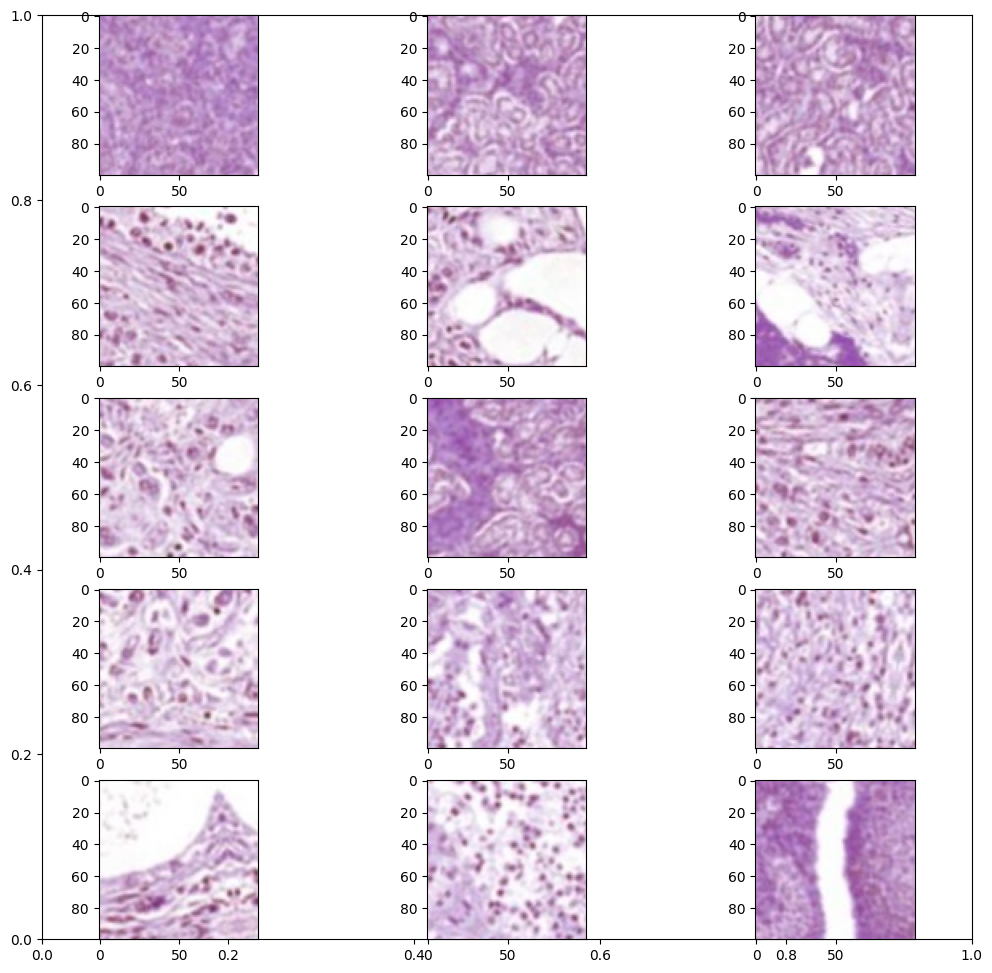

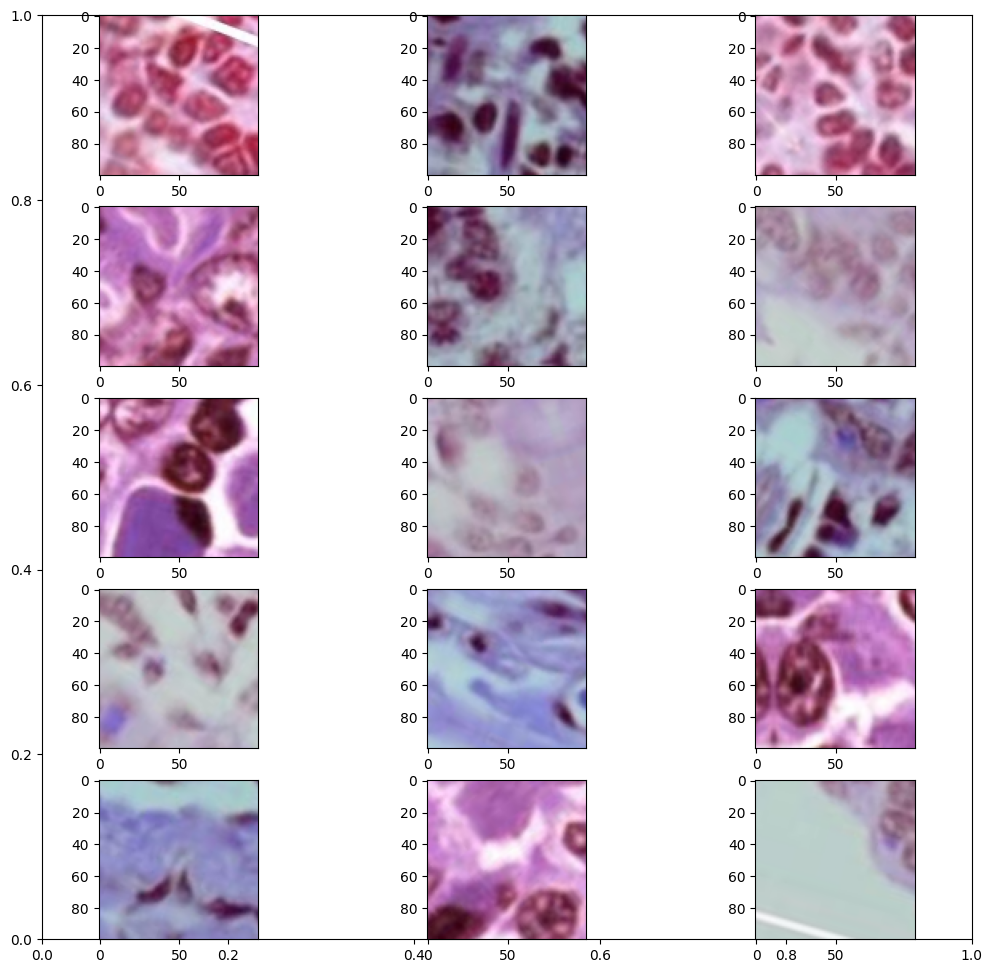

In [6]:
import matplotlib.pyplot as plt
# create a function to visualise of what the tile looks like when it will be fed into the CNN

def vis_gen(x, batch=0, name="generator.pdf"):

    plt.subplots(figsize=(12, 12))
    
    for i in range(0, 15):
        plt.subplot(5, 3, i + 1)
        for X_batch, Y_batch in x:
            image = X_batch[batch]
            plt.imshow(image)
            break
    plt.savefig(name)
    return "Done"

# preview the 10 training tiles from model 1 to see if they look correct
vis_gen(train1_flow, batch=0, name="train_images_AB.pdf")
# check for model 2 
vis_gen(train2_flow, batch=0, name="train_images_CD.pdf")

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import BatchNormalization, Conv2D, MaxPooling2D
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.optimizers import SGD

# ---------------- Model 3: The CNN framework  ----------------

# create a function that builds the convolutional neuronal network (CNN)
# there are two layers where each layer learns to see the image at different levels of complexity 
# therefore define the name of the model we are running 
def define_model(name="model"):
    model = Sequential(name=name) 
    # the first convolution layer scans the tile with 64 filters, it will look at one 3x3 pixel area at a time and slides 
    # across the whole tile
# -------- LAYER 1----------- 
    model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform', 
                     input_shape=(100, 100, 3))) # this tells the model is 100x100 pixels with 3 RGB channels
    # reduce the dimensions by keeping only the strongest signals in each 2x2 area --> makes sures the pattern exist
    model.add(MaxPooling2D((2, 2)))
    # this helps the model train faster as it keeps the values in a stable range 
    model.add(BatchNormalization())
    
# -------- LAYER 2 -----------    
    # create a second convolution layer - it now has 128 filters to detect more complex patterns 
    model.add(Conv2D(filters=128, kernel_size = (3,3), activation="relu")) 
    # reduce the dimensions again
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(BatchNormalization()) 

# -------- LAYER 3 ----------- 
    # for the previous layers the number of filters have doubled, to capture increasingly more complex patterns,
    # the same thing is done again (Bamelis, 2022)
    model.add(Conv2D(filters=256, kernel_size = (3,3), activation="relu")) 
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(BatchNormalization())
    
    model.add(Flatten())
    # to prevent overfitting use dropout. Here the amount of dropout is increased to 0.5 to see if the model
    # is underfitting, this value can also be decreased but firstly the model needs to be tested 
    # (Bamelis, 2022)
    model.add(Dropout(0.5))
    # combine everything the convolution layers detect and make predictions based off of those patterns 
    model.add(Dense(100, activation='relu', kernel_initializer='he_uniform'))
    # get the probability for group A or B (as it is model 1) 
    model.add(Dense(2, activation='softmax')) 
    
# -------- COMPILE ----------- 
    # SGD (stochastic gradient descent) reduces prediction errors by adjusting the model (1.5. Stochastic Gradient Descent, no date)
    # the learning rate was reduced from 0.01 to 0.001 for more precise and stable learning
    # (Bamelis, 2022)
    opt = SGD(learning_rate=0.001, momentum=0.9)
    # prepare the model for training by compiling
    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    
    return model # return the fully built model for training

# understanding convolutional layers: https://pyimagesearch.com/2018/12/31/keras-conv2d-and-convolutional-layers/

**Q1. What is the training and validation accuracy for model 1?**

In [8]:
# -------- Training model 1 ----------- 

# build CNN model using define_model() 
model1 = define_model(name="model_1_A_vs_B")

# print the summary of the model where each layer is shown - need to check if the structure looks correct before training
model1.summary()

# train the model on the training tiles and test on the testing set after each epoch 
# epoch = "one complete pass through the entire training dataset where every data sample is passed through the model
# and its parameters are updated based on the calculated error" (Epoch in Machine Learning, 00:55:17+00:00)
stats1 = model1.fit(train1_flow,
                     epochs=10, # the model sees the training files once - a lower epoch means a lesser chance of overfitting (Bamelis, 2022)
                     validation_steps=test1_flow.samples//10, # use 10 batches from the test set 
                     validation_data=test1_flow,
                     verbose=1) 

/opt/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "model_1_A_vs_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 49, 49, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 23, 23, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     2,560,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,932,910 (11.19 MB)

 Trainable params: 2,932,014 (11.18 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step - accuracy: 0.7649 - loss: 0.7031 - val_accuracy: 0.4750 - val_loss: 1.4257
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - accuracy: 0.8108 - loss: 0.8780 - val_accuracy: 0.4500 - val_loss: 1.1989
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.8459 - loss: 0.6183 - val_accuracy: 0.5000 - val_loss: 0.9570
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.8568 - loss: 0.4604 - val_accuracy: 0.5000 - val_loss: 1.5037
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.9108 - loss: 0.3381 - val_accuracy: 0.5250 - val_loss: 0.9534
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.9081 - loss: 0.2466 - val_accuracy: 0.5000 - val_loss: 2.5674
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.9162 - loss: 0.2634 - val_accuracy: 0.5250 - val_loss: 1.2788
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.9378 - loss: 0.1928 - val_accuracy: 0.

**RESULTS**: model 1 (A vs B) achieved a final training accuracy of 88.92% and a final validation accuracy of 77.50% after 10 epochs, with a final training loss of 0.29 and validation loss of 0.51. As shown in the training-epoch curve (question 3), training accuracy increased steadily throughout, however validation accuracy remaind iregular.

**Q2. What is the training and validation accuracy for model 2?**

In [9]:
# -------- Training model 2 ----------- 

model2 = define_model(name="model2_C_vs_D")


model2.summary()

stats2 = model2.fit(train2_flow,
                     epochs=10,
                     validation_steps=test2_flow.samples//10,
                     validation_data=test2_flow,
                     verbose=1)

Model: "model2_C_vs_D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 98, 98, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 49, 49, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 23, 23, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │     2,560,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,932,910 (11.19 MB)

 Trainable params: 2,932,014 (11.18 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.9574 - loss: 0.0981 - val_accuracy: 0.4333 - val_loss: 2.5042
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - accuracy: 0.9970 - loss: 0.0160 - val_accuracy: 1.0000 - val_loss: 0.0775
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.9878 - loss: 0.0808 - val_accuracy: 0.6000 - val_loss: 1.3938
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - accuracy: 0.9757 - loss: 0.0641 - val_accuracy: 0.9667 - val_loss: 0.0983
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.9909 - loss: 0.0121 - val_accuracy: 1.0000 - val_loss: 6.2120e-04
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 1.0000 - loss: 5.5333e-05 - val_accuracy: 0.9667 - val_loss: 0.0600
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.9939 - loss: 0.0422 - val_accuracy: 0.5333 - val_loss: 3.4160
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 0

**RESULTS**: Model 2 (C vs D) achieved a final training accuacy of 100% and a final validation accuracy of 96.67% after 10 epochs, with a final training loss of 0.0007 and validation loss of 0.079. As stated for model 1 the training-epoch curve shows the distribution of these metrics across the epochs. Results demonstrate minimal overfitting due to minimal gaps between the training and validation accuracy.

**Q3. Which off the models performed best on its dataset and suggest possible reasons for the differences in performance.**

In [11]:
# -------- TRAINING HISTORY ----------- 

# visually represent the accuracy and loss over 10 epochs
# a function is defined to plot the training history of model 1 and 2, this allows to visually see how accuracy 
# and loss has changed across each epoch during training 
def plot_model_stats(res, name): # res = results - will take the stats for the independently tested models and cross-testing models

    # -------- ACCURACY PLOT ---------
    plt.plot(res.history['accuracy'], label = 'train')
    plt.plot(res.history['val_accuracy'], label = 'validation')
    plt.title(f' {name} - accuracy')
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

    # -------- LOSS PLOT ---------
    plt.plot(res.history['loss'], label='train')
    plt.plot(res.history['val_loss'], label='validation')
    plt.title(f' {name} - loss')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

# code adapted from: https://stackoverflow.com/q/41908379

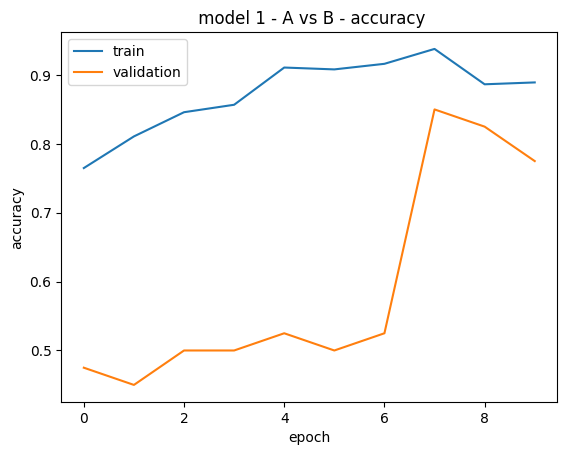

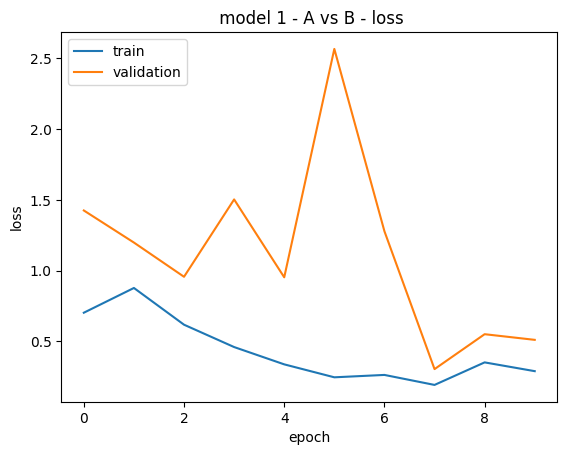

In [12]:
# call function - model 1
plot_model_stats(stats1, name="model 1 - A vs B")

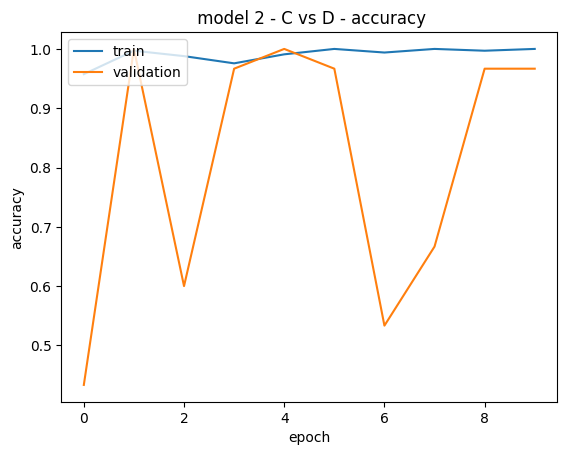

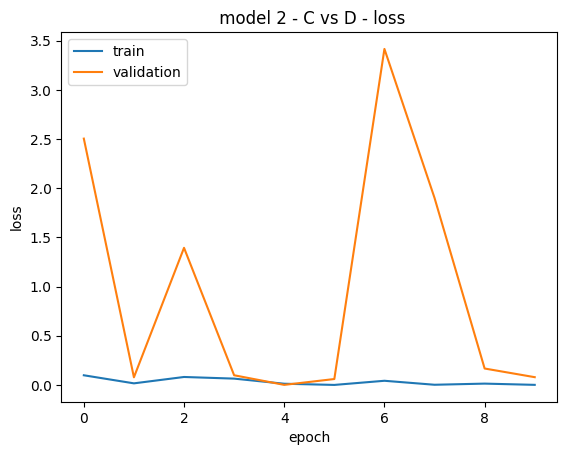

In [13]:
# call function - model 2
plot_model_stats(stats2, name="model 2 - C vs D")

In [15]:
print(f"Group A: {len(A1_cubes) + len(A2_cubes)} tiles")
print(f"Group B: {len(B1_cubes) + len(B2_cubes)} tiles")
print(f"Group C: {len(C1_cubes) + len(C2_cubes)} tiles")
print(f"Group D: {len(D1_cubes) + len(D2_cubes)} tiles")

Group A: 200 tiles
Group B: 212 tiles
Group C: 204 tiles
Group D: 162 tiles


**RESULTS**:\
Model 2 outperformed model 1 across all metrics. Model 1 achieved a final training accuracy of 88.92% and validation accuracy of 77.50%, while model 2 achieved a final training accuracy of 100% and validation of 96.67%. 

Looking at the training-epoch curves, model 1 showed a steady increase across all 10 epochs, however validation accuracy remained irregular and flat between 45-53% for the first 6 epochs before jumping to 85% at epoch 8 and dropping back to 77.50% by epoch 10. The persistent gap between training and validation accuracy suggests the model was overfitted. This is where the model had learned the training tiles well but are struggling to generaluse to unseen data. This is further supported by the validation loss, which spiked as high as 2.56 during training. 

Model 2 in contrast, had reached 100% accuracy by epoch 2 and maintaining strong validation accuracy for most of the training run, finishing at 96.67%. Although the validation curve showed some instability where accuracy dropped to 53% at epoch 6 (as seen in model2 - C vs D - accuracy). A reason for this could be due to a small test size of only 37 tiles (due to the split). 

Several factors likely contributed to the performance difference between the models. First, the groups in model 2 may be more visually disitnct from one another, making it easier for the CNN to learn discriminating features. This is supported by visual inspection of the training tiles. The A and B tiles displayed similar staining intensity and tissue architecture throughout, making visual discrimination difficult even by eye. In contrast, the C and D tiles showed differences in stanining colour and tissue morphology. A shift between deep pink and blue tones with different cellular structures is seen. This separation between the tile groups could explain why we have such a high accuracy for model 2, but overfitting for model 1 . Second, model 1's training set was more balanced (196 A vs 206 B tiles - as displayed above) but still produced poor validation performance, suggesting the visual similarity between A and B is the limiting factor rather than data quantity. Third, model 2's D group has fewer tiles (162 tiles) compared to C (204), yet the model still achieved high accuracy. 

**Q4. Test model 1 on test set 2 and model 2 on test set 1. Report the results**

In [16]:
# -------- Cross-test models ----------- 

# evaluate model 1 on test set from model 2
score1 = model1.evaluate(test2_flow, verbose=0)
print("Test loss:", score1[0]) # measure how wrong the predictions are (lower the better)
print("Test accuracy:", score1[1]) # measure how accurate the percentage of tiles are correctly predicted (higher the better) 

# evaluate model 2 on test set from model 1
score2 = model2.evaluate(test1_flow, verbose=0)
print("Test loss:", score2[0])
print("Test accuracy:", score2[1])

Test loss: 19.062232971191406
Test accuracy: 0.5675675868988037
Test loss: 17.23398208618164
Test accuracy: 0.4761904776096344


**RESULTS**:\
Model 1 (trained on A vs B) was evaluated on test set 2 (C and D image groups) and achieved an accuracy of 56.76% with a loss of 19.06. Model 2 (trained on C vs D) was evaluated on test set 1 (A and B image groups) and achieved an accuracy of 47.62% with a loss of 17.23. 

**5.	What are the possible explanations for the observations made in question 4 above.**

The cross-testing results revealed that model 1 achieved an accuracy of 56.76% (0.5675675868988037) on test set 2 (C/D image groups) and model 2 achieved an accuracy of 47.62% (0.4761904776096344) on test set 1 (A/B image groups). Both results represent near-random and below-random performance, which has several explanations. 

Firstly, the two models were trained on completely different classes. Model 1 only knows what A and B looks like, its output layer only has two neurons for these two classes. So when it is given group C and D images it has never seen before, it cannot output C or D as a prediction. It is forced to guess between A and B regardless of what the image its testing on consists of. The same applies to model 2 when tested on A and B images. This means the accuracy values in question 4 are invalid and do not reflect any real classification ability. The models are forced to guess. 

Furthermore, each model learns very specific visual features that are only useful for its own model. The patterns, textures, and cellular features that help distinguish A from B are completely different to those that distinguish C and D. When a model, trained on one tissue type, is applied to a different tissue type, the learned features of the model becomes irrelevant and the predictions again become invalid. The extremely high loss values (19.06 and 17.23) confirms the models are not only uncertain but also confidently wrong.

Lastly, data imbalance, as seen in our tiles for each group plays a crucial part in this model failure. It is seen that the tiles for group D has fewer than the other groups, this further reduces the reliability as it means the model becomes biased to certain groups just becomes they are more of them to learn from. 

From a clinical perspective, utilising a CNN model like this could be used to help cancer biopsies. However, these results highlights the limitations of using CNN-based tools. If deployed in real pahology settings, a model would still produce a confident prediction even on tissue it has never seen, with no warning to the clinican (Yao, Dong and Hwang, 2025). This could lead to misdiagnosis and patient harm. The risk is worsened by the lack of interpretibility in CNNs. When errors occur, the model cannot explain its reasoning, reducing trust amoung clinicians and patients (Yao, Dong and Hwang, 2025). Tools such as SHapley Additive exPlanations (SHAP) could help address this by identifying which specific image features are driving preditions, making the model more clinically meaningful (Yao, Dong and Hwang, 2025). Moreover, cross-centre generalisation also remains a significant challenge. Differences in scanning equipment, staining protocols, and imaging parameters between hospitals means different images of H&E are produced, and if a model is trained in one centre it could mean they fail in another, or on the same tissue type (Zhang and Yang, no date). This hypothetical is directly reflected in our results. As seen in the training tile visual, the A and B tiles displayed similar staining intensities and tissue architecture throughout, where pale purple and pink tones are presented. In contrast, the C and D tiles showed differences in both staining colour and tissue morphology, in the visual there are deep pink and blue tones with cellular structures. This variation between the two model groups therefore justifies why the cross-model testing failed, as the models were not only trained on different groups but on visually and structurally different tissue types entirely. In a real clinical setting, this would be like using a model trained on one type of cancer tissue to analyse a completely different type, the model would still produce a prediction without knowing what cancer tissue type it is, putting patients at risk (Yao, Dong and Hwang, 2025). 

REFERENCES:

1.	1.5. Stochastic Gradient Descent (no date) scikit-learn. Available at: https://scikit-learn/stable/modules/sgd.html (Accessed: 30 April 2026).
https://qmplus.qmul.ac.uk/course/section.php?id=1355362.
2.	Bamelis, M. (2022) ‘Answer to “How to improve the performance of CNN Model for a specific Dataset? Getting Low Accuracy on both training and Testing Dataset”’, Stack Overflow. Available at: https://stackoverflow.com/a/70579136 (Accessed: 30 April 2026).
3.	Data types — NumPy v2.4 Manual (no date). Available at: https://numpy.org/doc/stable/user/basics.types.html (Accessed: 29 April 2026).
4.	Epoch in Machine Learning (00:55:17+00:00) GeeksforGeeks. Available at: https://www.geeksforgeeks.org/machine-learning/epoch-in-machine-learning/ (Accessed: 30 April 2026).
5.	J, V. (2019) ‘Tutorial on Keras flow_from_dataframe’, Medium, 27 April. Available at: https://vijayabhaskar96.medium.com/tutorial-on-keras-flow-from-dataframe-1fd4493d237c (Accessed: 30 April 2026).
6.	Kani, S.N. et al. (2025) ‘Tissue Region Segmentation in H&amp;E-Stained and IHC-Stained Pathology Slides of Specimens from Different Origins’. medRxiv, p. 2025.01.16.25320663. Available at: https://doi.org/10.1101/2025.01.16.25320663.
7.	Rosebrock, A. (2018) ‘Keras Conv2D and Convolutional Layers’, PyImageSearch, 31 December. Available at: https://pyimagesearch.com/2018/12/31/keras-conv2d-and-convolutional-layers/ (Accessed: 30 April 2026).
8.	Rosebrock, A. (2019) ‘Keras ImageDataGenerator and Data Augmentation’, PyImageSearch, 8 July. Available at: https://pyimagesearch.com/2019/07/08/keras-imagedatagenerator-and-data-augmentation/ (Accessed: 30 April 2026).
9.	Yao, I.Z., Dong, M. and Hwang, W.Y.K. (2025) ‘Deep Learning Applications in Clinical Cancer Detection: A Review of Implementation Challenges and Solutions’, Mayo Clinic Proceedings: Digital Health, 3(3). Available at: https://doi.org/10.1016/j.mcpdig.2025.100253.
10.	Zhang, P. and Yang, Z. (no date) ‘Convolutional neural networks: applications, challenges and future prospects in brain tumor research’, Frontiers in Neurology, 17, p. 1759459. Available at: https://doi.org/10.3389/fneur.2026.1759459.


